# 원하는 포즈로 이미지 만들기 — OpenPose 포즈 조건 튜토리얼 (Colab + ComfyUI)

참조 사진 한 장에서 **사람의 관절(뼈대)** 을 뽑고, 그 뼈대를 조건으로 넣어 **같은 자세의 다른 인물·장면** 을 만드는 도구입니다.

수업 실습 노트(FLUX.2-klein-4B + ComfyUI)를 출발점으로, 아래를 더했습니다.

| 추가한 것 | 하는 일 |
|---|---|
| 참조 사진 불러오기 | 퍼블릭 도메인 사진을 URL로 받거나, 내 사진을 업로드 |
| OpenPose 포즈 추출 | 사진에서 관절 18개를 찾아 색깔 막대 뼈대 그림으로 저장 |
| **방식 A** — SD1.5 + OpenPose ControlNet | 뼈대를 ControlNet에 넣어 자세를 강제로 따르게 함 (정식 포즈 제어) |
| **방식 B** — FLUX.2-klein-4B + 참조 이미지 | 뼈대 그림을 klein의 참조 이미지(ReferenceLatent)로 넣음 (ControlNet 없이 시도) |
| **직접 써 보기 (Gradio)** | 사진 올리기 → 프롬프트 → 버튼으로 같은 자세의 이미지를 만드는 웹 화면 |
| 조건 실험 | ① 같은 포즈 + 다른 프롬프트 ② 같은 프롬프트 + 다른 포즈 |
| 기록 | 결과 PNG, 사용한 프롬프트·시드·모델을 `samples/`, `prompts.md`, `samples/log.json` 에 저장 |

### 왜 방식이 두 개인가?
- FLUX.2 계열에는 2026년 현재 **BFL 공식 OpenPose ControlNet이 없습니다.** 커뮤니티 ControlNet(FLUX.2-dev-Fun-Controlnet-Union)은 dev(32B) 기반이라 무료 T4에 올라가지 않습니다.
- 그래서 **자세를 확실히 따르는 정식 ControlNet(SD1.5)** 과 **수업에서 쓴 klein 4B의 참조 이미지 기능** 을 나란히 돌려, 어느 쪽이 포즈를 더 잘 지키는지 직접 비교합니다.

### 전체 흐름
```
참조 사진 ──(OpenPose)──▶ 뼈대 그림 pose_XX.png
                              │
           ┌──────────────────┴──────────────────┐
   방식 A: SD1.5 + ControlNet              방식 B: FLUX.2-klein + ReferenceLatent
           └──────────────▶ 결과 output_XX.png ◀──┘
```

### 실행 순서
1. 상단 메뉴 **[런타임 → 런타임 유형 변경 → T4 GPU]** 선택 후 저장
2. 위에서부터 셀을 **순서대로** 실행 (첫 실행은 모델 다운로드 약 14GB로 5~10분)
   - **바로 써 보기만 하려면**: 단계 1~10 실행 → 단계 10 아래에 뜨는 화면에서 사진을 올리고 버튼
   - **실험까지 하려면**: 단계 11~15 (기본 결과 + 실험 ①②③ + 기록 저장)
3. 마지막 셀의 **관찰 기록** 을 결과를 보며 채우기

> 라이선스: 실습 사진은 미국 국립공원관리청(Joshua Tree National Park)이 공개한 **퍼블릭 도메인** 사진입니다. FLUX.2-klein-4B는 Apache 2.0, SD1.5는 CreativeML OpenRAIL-M, ControlNet 1.1은 OpenRAIL 라이선스입니다.

## [단계 1] GPU 확인
이 셀이 하는 일: 런타임에 GPU가 붙었는지, 종류와 VRAM(그래픽카드 메모리)이 얼마인지 확인합니다. GPU가 없으면 이후 셀이 모두 실패하므로 여기서 멈춥니다.

In [7]:
# [단계 1] GPU 확인
import torch

print("PyTorch 버전:", torch.__version__)
if not torch.cuda.is_available():
    raise RuntimeError("GPU가 없습니다. [런타임 → 런타임 유형 변경 → T4 GPU] 후 다시 실행하세요.")
p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} / VRAM {p.total_memory / 1024**3:.1f}GB")

PyTorch 버전: 2.14.1+cu130
GPU: Tesla T4 / VRAM 14.6GB


## [단계 2] ComfyUI + GGUF 노드 + OpenPose 추출기 설치
이 셀이 하는 일:
- **ComfyUI** — 노드를 이어 붙여 이미지 생성 파이프라인을 만드는 도구. 여기서는 화면 없이 API 서버로만 씁니다.
- **ComfyUI-GGUF** — 4비트로 줄인(양자화) FLUX.2-klein 모델 파일(.gguf)을 읽는 플러그인.
- **controlnet_aux** — 사진에서 사람 관절을 찾는 **OpenPose** 추출기가 들어 있는 라이브러리.

In [8]:
# [단계 2] 설치 (이미 설치돼 있으면 건너뜀)
import os

%cd /content
if not os.path.isdir("/content/ComfyUI"):
    !git clone -q https://github.com/comfyanonymous/ComfyUI.git      # ComfyUI 본체
%cd /content/ComfyUI
!pip install -q -r requirements.txt                                  # ComfyUI 의존성

if not os.path.isdir("/content/ComfyUI/custom_nodes/ComfyUI-GGUF"):
    !git clone -q https://github.com/city96/ComfyUI-GGUF.git /content/ComfyUI/custom_nodes/ComfyUI-GGUF
!pip install -q gguf                                                 # GGUF 파서

!pip install -q controlnet_aux                                       # OpenPose 추출기
print("\n완료: ComfyUI + GGUF 노드 + controlnet_aux 설치")

/content
/content/ComfyUI

완료: ComfyUI + GGUF 노드 + controlnet_aux 설치


## [단계 3] 모델 파일 다운로드
이 셀이 하는 일: 두 방식에 필요한 파일을 ComfyUI 표준 폴더에 받습니다. 이미 받은 파일은 건너뜁니다.

| 방식 | 역할 | 파일 | 크기 |
|---|---|---|---|
| B | 디퓨전 모델 (4B, 4비트 양자화) | flux-2-klein-4b-Q4_K_M.gguf | 2.5GB |
| B | 텍스트 인코더 (Qwen3-4B, **언어모델**) | qwen_3_4b.safetensors | 7.5GB |
| B | VAE (latent ↔ 픽셀) | flux2-vae.safetensors | 0.3GB |
| A | SD1.5 체크포인트 (모델+CLIP 텍스트 인코더+VAE 한 파일) | v1-5-pruned-emaonly-fp16.safetensors | 2.1GB |
| A | **OpenPose ControlNet** | control_v11p_sd15_openpose_fp16.safetensors | 0.7GB |

> 두 방식의 텍스트 인코더가 다르다는 점을 기억해 두세요. SD1.5는 2021년식 **CLIP**(77토큰 제한), klein은 **현역 언어모델 Qwen3**입니다. 실험에서 같은 문장을 넣었을 때 차이가 나는 이유 중 하나입니다.

In [9]:
# [단계 3] 모델 다운로드
import os
%cd /content/ComfyUI

def 다운로드(url, 저장경로):
    # 이미 받았으면 건너뛰고, 아니면 wget 으로 받는 헬퍼
    os.makedirs(os.path.dirname(저장경로), exist_ok=True)
    if os.path.exists(저장경로) and os.path.getsize(저장경로) > 1_000_000:
        print(f"  ↳ 이미 있음: {저장경로} ({os.path.getsize(저장경로)/1e9:.2f} GB)")
        return
    print(f"  ↳ 다운로드 중: {저장경로}")
    !wget -q --show-progress -O "{저장경로}" "{url}"
    # 주소가 바뀌어 빈 파일이 받아지는 경우를 바로 잡아낸다
    if os.path.getsize(저장경로) < 1_000_000:
        os.remove(저장경로)
        raise RuntimeError(f"다운로드 실패(파일이 비어 있음): {url}")

HF = "https://huggingface.co"
print("[방식 B] FLUX.2-klein-4B 3종")
다운로드(f"{HF}/unsloth/FLUX.2-klein-4B-GGUF/resolve/main/flux-2-klein-4b-Q4_K_M.gguf",
       "models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf")
다운로드(f"{HF}/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/text_encoders/qwen_3_4b.safetensors",
       "models/text_encoders/qwen_3_4b.safetensors")
다운로드(f"{HF}/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/vae/flux2-vae.safetensors",
       "models/vae/flux2-vae.safetensors")

print("[방식 A] SD1.5 + OpenPose ControlNet")
다운로드(f"{HF}/Comfy-Org/stable-diffusion-v1-5-archive/resolve/main/v1-5-pruned-emaonly-fp16.safetensors",
       "models/checkpoints/v1-5-pruned-emaonly-fp16.safetensors")
다운로드(f"{HF}/comfyanonymous/ControlNet-v1-1_fp16_safetensors/resolve/main/control_v11p_sd15_openpose_fp16.safetensors",
       "models/controlnet/control_v11p_sd15_openpose_fp16.safetensors")

!ls -lh models/diffusion_models models/text_encoders models/vae models/checkpoints models/controlnet | grep -v "^total"

/content/ComfyUI
[방식 B] FLUX.2-klein-4B 3종
  ↳ 이미 있음: models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf (2.60 GB)
  ↳ 이미 있음: models/text_encoders/qwen_3_4b.safetensors (8.04 GB)
  ↳ 이미 있음: models/vae/flux2-vae.safetensors (0.34 GB)
[방식 A] SD1.5 + OpenPose ControlNet
  ↳ 다운로드 중: models/checkpoints/v1-5-pruned-emaonly-fp16.safetensors
models/checkpoints/ 100%[===================>]   1.99G   101MB/s    in 22s     
  ↳ 이미 있음: models/controlnet/control_v11p_sd15_openpose_fp16.safetensors (0.72 GB)
models/checkpoints:
-rw-r--r-- 1 root root    0 Nov 11 04:38 put_checkpoints_here
-rw-r--r-- 1 root root 2.0G Nov 11 04:46 v1-5-pruned-emaonly-fp16.safetensors

models/controlnet:
-rw-r--r-- 1 root root 690M Nov 11 04:42 control_v11p_sd15_openpose_fp16.safetensors
-rw-r--r-- 1 root root    0 Nov 11 04:38 put_controlnets_and_t2i_here

models/diffusion_models:
-rw-r--r-- 1 root root 2.5G Nov 11 04:40 flux-2-klein-4b-Q4_K_M.gguf
-rw-r--r-- 1 root root    0 Nov 11 04:38 put_diffusion_model_files_her

## [단계 4] ComfyUI 서버 실행
이 셀이 하는 일: ComfyUI를 백그라운드에서 띄웁니다. 이후 셀들은 `http://127.0.0.1:8188` 로 생성 요청(워크플로 JSON)을 보내고 결과 이미지를 받아 옵니다. `200` 응답이 오면 준비 완료입니다.

In [10]:
# [단계 4] ComfyUI 서버 실행
import subprocess, os, time
%cd /content/ComfyUI

!pkill -f "main.py --listen" 2>/dev/null
time.sleep(2)
os.system("nohup python main.py --listen 127.0.0.1 --port 8188 > /content/comfyui.log 2>&1 &")

print("ComfyUI 기동 대기 중...")
for _ in range(90):
    time.sleep(1)
    code = subprocess.run("curl -s -o /dev/null -w '%{http_code}' http://127.0.0.1:8188/",
                          shell=True, capture_output=True, text=True).stdout
    if code == "200":
        print("완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)")
        break
else:
    print("서버가 안 뜹니다. 로그 마지막 부분:")
    print(open("/content/comfyui.log").read()[-1500:])

/content/ComfyUI
^C
ComfyUI 기동 대기 중...
완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)


## [단계 5] 공통 도구 함수
이 셀이 하는 일: 뒤에서 반복해 쓸 함수를 정의합니다. (실행해도 아무것도 생성되지 않습니다)

| 함수 | 하는 일 |
|---|---|
| `upload(path)` | 로컬 이미지를 ComfyUI 입력 폴더로 올림 (LoadImage 노드가 읽을 수 있게) |
| `run(workflow)` | 워크플로 JSON을 보내고, 끝날 때까지 기다렸다가 결과 이미지를 PIL로 돌려줌 |
| `size_for(img, base)` | 참조 사진 비율을 유지하면서 64의 배수 크기를 계산 |
| `log_result(...)` | 프롬프트·시드·모델·파일명을 `samples/log.json` 에 누적 기록 (재현용) |
| `reset_log(실험)` | 셀을 다시 실행할 때 그 실험의 예전 기록을 지워 중복을 막음 |
| `show(images, titles)` | 여러 장을 나란히 보여 주고 비교 그림으로 저장 |

In [21]:
# [단계 5] 공통 도구 함수
import requests, time, json, os, io, urllib.parse
from PIL import Image
import matplotlib.pyplot as plt

SERVER  = "http://127.0.0.1:8188"
SAMPLES = "/content/pose-image-tool/samples"
os.makedirs(SAMPLES, exist_ok=True)
LOG_PATH = f"{SAMPLES}/log.json"

def upload(path):
    # 이미지를 ComfyUI input 폴더로 업로드하고, 노드에서 쓸 파일 이름을 돌려준다
    with open(path, "rb") as f:
        r = requests.post(f"{SERVER}/upload/image",
                          files={"image": (os.path.basename(path), f, "image/png")},
                          data={"overwrite": "true"}, timeout=60)
    r.raise_for_status()
    return r.json()["name"]

def run(workflow, save_node, timeout_s=600):
    # 워크플로 전송 → 완료까지 폴링 → 결과 이미지(PIL) 반환
    r = requests.post(f"{SERVER}/prompt", json={"prompt": workflow, "client_id": "pose-tool"}, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"요청 실패 {r.status_code}: {r.text[:800]}")
    pid, t0 = r.json()["prompt_id"], time.time()
    while time.time() - t0 < timeout_s:
        time.sleep(1.5)
        h = requests.get(f"{SERVER}/history/{pid}", timeout=10).json()
        if pid not in h:
            continue
        entry = h[pid]
        if entry.get("status", {}).get("status_str") == "error":
            raise RuntimeError("ComfyUI 실행 에러: " + json.dumps(entry["status"].get("messages", []), ensure_ascii=False)[:1500])
        img = entry["outputs"][save_node]["images"][0]
        q = urllib.parse.urlencode({"filename": img["filename"], "subfolder": img.get("subfolder", ""), "type": img.get("type", "output")})
        data = requests.get(f"{SERVER}/view?{q}", timeout=30).content
        print(f"  생성 완료 {time.time()-t0:.1f}초")
        return Image.open(io.BytesIO(data)).convert("RGB")
    raise TimeoutError("생성 시간 초과")

def size_for(img, base):
    # 가로를 base로 두고, 원본 비율을 유지한 세로를 64의 배수로 맞춘다
    w, h = img.size
    return base, max(64, round(base * h / w / 64) * 64)

def log_result(**kw):
    logs = json.load(open(LOG_PATH)) if os.path.exists(LOG_PATH) else []
    logs.append(kw)
    json.dump(logs, open(LOG_PATH, "w"), ensure_ascii=False, indent=2)

def reset_log(experiment):
    # 같은 실험 셀을 다시 실행해도 기록이 중복되지 않도록, 그 실험의 예전 기록을 지운다
    if os.path.exists(LOG_PATH):
        logs = [L for L in json.load(open(LOG_PATH)) if L.get("experiment", "기본") != experiment]
        json.dump(logs, open(LOG_PATH, "w"), ensure_ascii=False, indent=2)

def show(images, titles, save_as=None, cols=None):
    cols = cols or len(images)
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.6 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t in zip(axes.flat, images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=9)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=110, bbox_inches="tight")
    plt.show()

print("도구 함수 준비 완료")

도구 함수 준비 완료


## [단계 6] 참조 사진 준비
이 셀이 하는 일: 포즈를 따올 사람 사진 3장을 받아 `samples/ref_01~03.jpg` 로 저장합니다.

- 기본값은 Joshua Tree 국립공원이 공개한 **퍼블릭 도메인** 사진 3장입니다(서서 균형 잡기 2장 + 쪼그려 앉기 1장).
- 처음에는 3번으로 요가 '다운독'(엎드려 ㅅ자) 사진을 썼는데, 머리가 아래로 가고 얼굴이 가려져 **OpenPose가 관절을 하나도 찾지 못했습니다.** 그래서 쪼그려 앉은 사진으로 바꿨습니다. (README의 한계 참고)
- **내 사진을 쓰려면** `MY_UPLOAD = True` 로 바꾸고 실행하면 업로드 창이 뜹니다. 단, 공개 저장소에 올릴 때는 얼굴·권리를 확인하세요.
- **좋은 참조 사진의 조건**: 전신이 다 보이고, 사람 한 명, 팔다리가 몸에 가려지지 않은 사진. 손이 작게 찍히면 손가락 관절은 잘 안 잡힙니다.

/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 50577 (\N{HANGUL SYLLABLE YANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 54036 (\N{HANGUL SYLLABLE PAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 51012 (\N{HANGUL SYLLABLE EUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 48268 (\N{HANGUL SYLLABLE BEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 54620 (\N{HANGUL SYLLABLE HAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/i

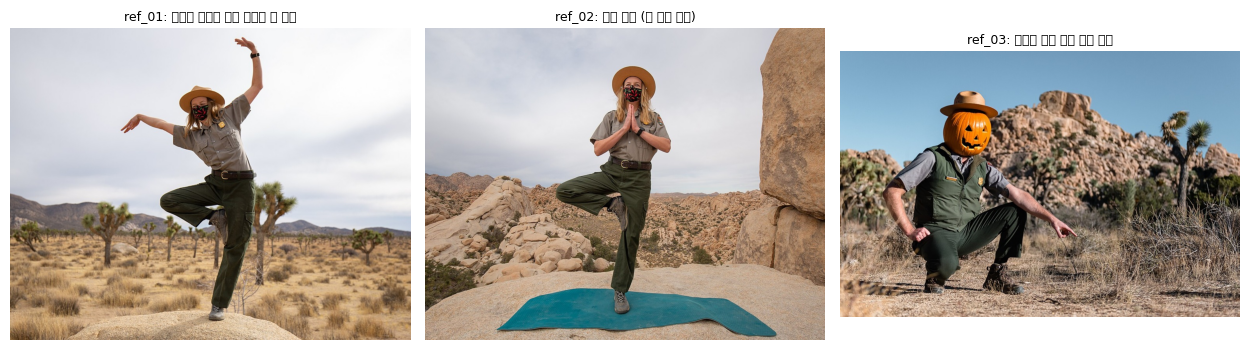

In [22]:
# [단계 6] 참조 사진 준비
import requests, os, io, time
from PIL import Image

MY_UPLOAD = False   # True 로 바꾸면 내 사진을 업로드해서 사용

REFS = [  # (설명, 위키미디어 공용 파일명) — 모두 Public domain, 출처: Joshua Tree National Park / Wikimedia Commons
    ("양팔을 벌리고 한쪽 다리를 든 자세", "Park_Ranger_in_Joshua_Tree_Yoga_Pose_(50695377468).jpg"),
    ("나무 자세 (한 발로 서기)",          "Park_Ranger_in_Joshua_Tree_Yoga_Pose_(50696134541).jpg"),
    ("쪼그려 앉아 팔을 벌린 자세",          "Ranger_Jack_O'Lantern_(52464647862).jpg"),
]
HEADERS = {"User-Agent": "pose-image-tool-colab/1.0 (educational notebook)"}  # 위키미디어는 UA 표기를 요구

def 위키미디어_받기(파일명, width=1024, 재시도=5):
    # 원본(수 MB) 대신 1024px 썸네일을 받는다. 클라우드 IP는 429(요청 과다)가 잦아 기다렸다 재시도
    url = f"https://commons.wikimedia.org/wiki/Special:FilePath/{파일명}?width={width}"
    for n in range(재시도):
        r = requests.get(url, headers=HEADERS, timeout=60)
        if r.status_code == 429:
            wait = int(r.headers.get("Retry-After", 0) or 0) or 5 * (n + 1)
            print(f"  429 요청 과다 → {wait}초 뒤 재시도 ({n+1}/{재시도})"); time.sleep(wait); continue
        r.raise_for_status()
        return Image.open(io.BytesIO(r.content)).convert("RGB")
    raise RuntimeError("위키미디어 다운로드 실패. MY_UPLOAD = True 로 바꿔 사진을 직접 올리세요.")

ref_paths = []
if MY_UPLOAD:
    from google.colab import files
    up = files.upload()
    for i, name in enumerate(up, 1):
        p = f"{SAMPLES}/ref_{i:02d}.jpg"
        Image.open(name).convert("RGB").save(p, quality=92)
        ref_paths.append((name, p))
else:
    for i, (desc, 파일명) in enumerate(REFS, 1):
        p = f"{SAMPLES}/ref_{i:02d}.jpg"
        img = 위키미디어_받기(파일명)              # REFS 를 바꾸면 바로 반영되도록 매번 받는다
        img.thumbnail((1024, 1024))                # 긴 변 1024px 로 맞춰 저장
        img.save(p, quality=92)
        time.sleep(1)                              # 연속 요청 간격
        ref_paths.append((desc, p))

show([Image.open(p) for _, p in ref_paths], [f"ref_{i:02d}: {d}" for i, (d, _) in enumerate(ref_paths, 1)])

## [단계 7] OpenPose로 관절(뼈대) 추출
이 셀이 하는 일: 각 참조 사진에서 OpenPose가 관절 18개(코·목·어깨·팔꿈치·손목·골반·무릎·발목·눈·귀)를 찾고, 이를 **검은 바탕 위의 색깔 막대 그림**으로 그려 `samples/pose_XX.png` 로 저장합니다.

이 색깔 그림이 바로 ControlNet이 읽는 "포즈 조건"입니다. 막대 색이 신체 부위를 뜻하기 때문에(예: 오른팔/왼팔 색이 다름) 좌우까지 구분됩니다.

> `controlnet_aux` 는 버전에 따라 다른 추출기(깊이·선화 등)를 한꺼번에 불러오다 실패할 때가 있어, 실패하면 OpenPose 부분만 따로 불러오도록 해 두었습니다.

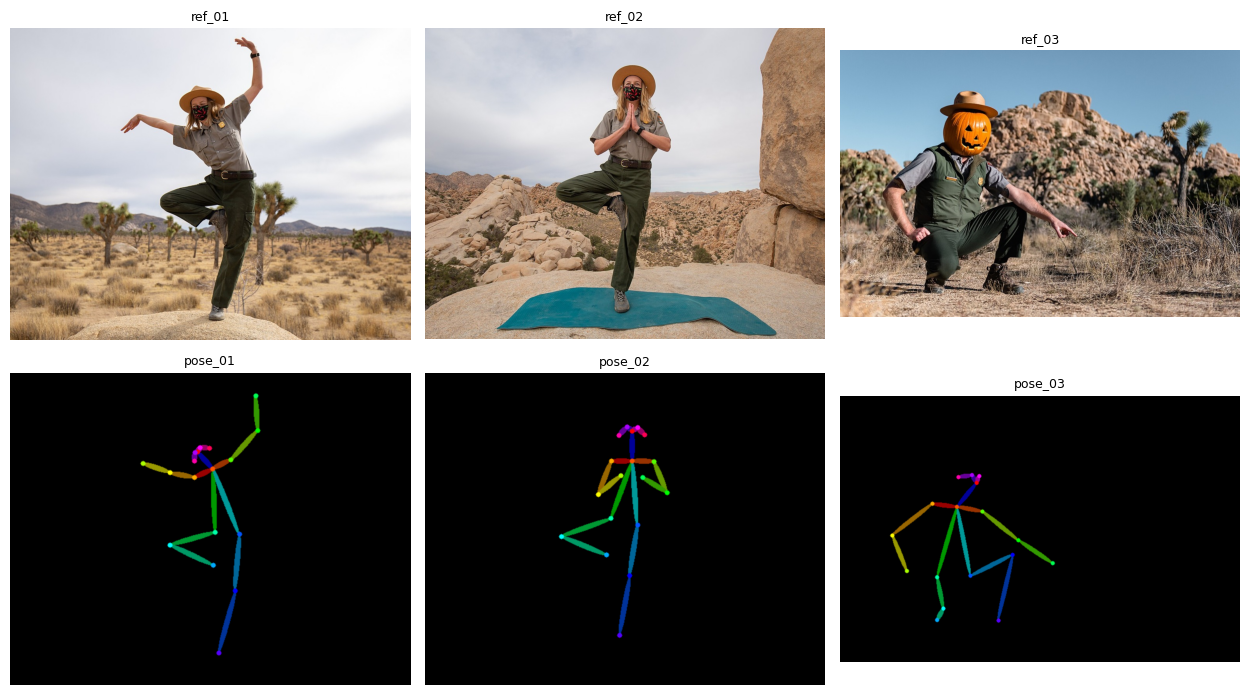

In [23]:
# [단계 7] OpenPose 관절 추출
import sys, types, importlib, importlib.util

# 최신 SciPy 에서 사라진 옛 경로(scipy.ndimage.filters)를 쓰는 코드 대비
import scipy.ndimage
sys.modules.setdefault("scipy.ndimage.filters", scipy.ndimage)

try:
    from controlnet_aux import OpenposeDetector
except Exception as e:
    # 패키지 전체 import 가 실패하면 open_pose 하위 모듈만 직접 불러온다
    print("controlnet_aux 전체 import 실패 → OpenPose만 불러옵니다:", type(e).__name__, str(e)[:120])
    for k in [k for k in sys.modules if k.startswith("controlnet_aux")]:
        del sys.modules[k]
    spec = importlib.util.find_spec("controlnet_aux")
    pkg = types.ModuleType("controlnet_aux"); pkg.__path__ = list(spec.submodule_search_locations)
    sys.modules["controlnet_aux"] = pkg
    OpenposeDetector = importlib.import_module("controlnet_aux.open_pose").OpenposeDetector

openpose = OpenposeDetector.from_pretrained("lllyasviel/Annotators")   # body_pose_model.pth 자동 다운로드

pose_paths = []
for i, (desc, ref_p) in enumerate(ref_paths, 1):
    ref = Image.open(ref_p).convert("RGB")
    # include_hand / include_face 를 끄면 몸통 18관절만 그림 (손가락은 작아서 잘 안 잡힘)
    pose = openpose(ref, detect_resolution=512, image_resolution=ref.width,
                    include_body=True, include_hand=False, include_face=False)
    pose = pose.resize(ref.size)                      # 참조 사진과 같은 크기·비율로 맞춤
    p = f"{SAMPLES}/pose_{i:02d}.png"
    pose.save(p)
    pose_paths.append(p)

show([Image.open(p) for _, p in ref_paths] + [Image.open(p) for p in pose_paths],
     [f"ref_{i:02d}" for i in range(1, 4)] + [f"pose_{i:02d}" for i in range(1, 4)],
     save_as=f"{SAMPLES}/compare_ref_vs_pose.png", cols=3)

## [단계 8] 생성 함수 — 방식 A(SD1.5 ControlNet) / 방식 B(FLUX.2-klein 참조)
이 셀이 하는 일: 두 방식의 ComfyUI 워크플로를 함수로 만듭니다. (실행해도 아직 생성은 안 합니다)

**방식 A — SD1.5 + OpenPose ControlNet**
```
체크포인트 → 프롬프트 인코딩(CLIP) ─┐
뼈대 그림 → ControlNet 적용 ────────┴→ KSampler(25스텝, cfg 7) → VAE 디코드 → 저장
```
- `strength` : 포즈를 얼마나 강하게 따를지 (0~2, 기본 1.0)

**방식 B — FLUX.2-klein-4B + ReferenceLatent**
```
GGUF 모델 → 프롬프트 인코딩(Qwen3) → ReferenceLatent(뼈대 그림을 VAE로 인코딩해 참조로 붙임) → KSampler(4스텝) → 저장
```
- klein은 "참조 이미지를 보고 고쳐 그리는" 편집 기능이 있어서, 뼈대 그림을 참조로 주고 *"이 막대 인형과 같은 자세로"* 라고 지시합니다. 정식 포즈 제어는 아니라서 따르는 정도가 들쭉날쭉할 수 있는데, 그것을 관찰하는 것이 실험 목적입니다.
- 스텝·cfg는 수업 노트와 같게 4스텝, cfg 4.0 으로 둡니다.

In [14]:
# [단계 8] 두 방식의 생성 함수
SEED = 42   # 시드 고정 → 바뀐 것이 프롬프트/포즈 때문이라고 말할 수 있다

SD_CKPT = "v1-5-pruned-emaonly-fp16.safetensors"
SD_CN   = "control_v11p_sd15_openpose_fp16.safetensors"

def gen_sd_controlnet(prompt, pose_path, negative="", strength=1.0, steps=25, cfg=7.0, seed=SEED, base=640):
    # 방식 A: SD1.5 + OpenPose ControlNet
    pose_img = Image.open(pose_path)
    w, h = size_for(pose_img, base)
    name = upload(pose_path)
    wf = {
        "1":  {"class_type": "CheckpointLoaderSimple", "inputs": {"ckpt_name": SD_CKPT}},                 # 모델+CLIP+VAE
        "2":  {"class_type": "CLIPTextEncode", "inputs": {"text": prompt, "clip": ["1", 1]}},             # 프롬프트
        "3":  {"class_type": "CLIPTextEncode", "inputs": {"text": negative, "clip": ["1", 1]}},           # 네거티브
        "4":  {"class_type": "ControlNetLoader", "inputs": {"control_net_name": SD_CN}},                  # 포즈 ControlNet
        "5":  {"class_type": "LoadImage", "inputs": {"image": name}},                                     # 뼈대 그림
        "6":  {"class_type": "ControlNetApplyAdvanced", "inputs": {                                       # 조건에 포즈 주입
                  "positive": ["2", 0], "negative": ["3", 0], "control_net": ["4", 0], "image": ["5", 0],
                  "strength": strength, "start_percent": 0.0, "end_percent": 1.0}},
        "7":  {"class_type": "EmptyLatentImage", "inputs": {"width": w, "height": h, "batch_size": 1}},
        "8":  {"class_type": "KSampler", "inputs": {"seed": seed, "steps": steps, "cfg": cfg,
                  "sampler_name": "dpmpp_2m", "scheduler": "karras", "denoise": 1.0,
                  "model": ["1", 0], "positive": ["6", 0], "negative": ["6", 1], "latent_image": ["7", 0]}},
        "9":  {"class_type": "VAEDecode", "inputs": {"samples": ["8", 0], "vae": ["1", 2]}},
        "10": {"class_type": "SaveImage", "inputs": {"images": ["9", 0], "filename_prefix": "sd_pose"}},
    }
    return run(wf, "10"), dict(method="A: SD1.5 + OpenPose ControlNet", model=f"{SD_CKPT} + {SD_CN}",
                              seed=seed, steps=steps, cfg=cfg, strength=strength, size=f"{w}x{h}", negative=negative)

KLEIN_POSE_HINT = ("The reference image is a stick-figure pose skeleton. "
                   "Draw a new photo where the subject matches that exact body pose, limb positions and framing. "
                   "Do not draw the skeleton itself. ")

def gen_klein_reference(prompt, ref_path, steps=4, cfg=4.0, seed=SEED, base=1024, hint=KLEIN_POSE_HINT):
    # 방식 B: FLUX.2-klein-4B + ReferenceLatent (참조 이미지로 포즈 전달)
    ref_img = Image.open(ref_path)
    w, h = size_for(ref_img, base)
    name = upload(ref_path)
    wf = {
        "10": {"class_type": "UnetLoaderGGUF", "inputs": {"unet_name": "flux-2-klein-4b-Q4_K_M.gguf"}},
        "8":  {"class_type": "CLIPLoader", "inputs": {"clip_name": "qwen_3_4b.safetensors", "type": "flux2"}},
        "6":  {"class_type": "CLIPTextEncode", "inputs": {"text": hint + prompt, "clip": ["8", 0]}},
        "7":  {"class_type": "CLIPTextEncode", "inputs": {"text": "", "clip": ["8", 0]}},
        "4":  {"class_type": "VAELoader", "inputs": {"vae_name": "flux2-vae.safetensors"}},
        "20": {"class_type": "LoadImage", "inputs": {"image": name}},
        "21": {"class_type": "ImageScale", "inputs": {"image": ["20", 0], "upscale_method": "lanczos",
                  "width": w, "height": h, "crop": "disabled"}},
        "22": {"class_type": "VAEEncode", "inputs": {"pixels": ["21", 0], "vae": ["4", 0]}},            # 참조 → latent
        "23": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["6", 0], "latent": ["22", 0]}},  # 참조 부착
        "5":  {"class_type": "EmptyLatentImage", "inputs": {"width": w, "height": h, "batch_size": 1}},
        "3":  {"class_type": "KSampler", "inputs": {"seed": seed, "steps": steps, "cfg": cfg,
                  "sampler_name": "euler", "scheduler": "simple", "denoise": 1.0,
                  "model": ["10", 0], "positive": ["23", 0], "negative": ["7", 0], "latent_image": ["5", 0]}},
        "9":  {"class_type": "VAEDecode", "inputs": {"samples": ["3", 0], "vae": ["4", 0]}},
        "11": {"class_type": "SaveImage", "inputs": {"images": ["9", 0], "filename_prefix": "klein_pose"}},
    }
    return run(wf, "11"), dict(method="B: FLUX.2-klein-4B + ReferenceLatent", model="flux-2-klein-4b-Q4_K_M.gguf",
                              seed=seed, steps=steps, cfg=cfg, size=f"{w}x{h}", hint=hint.strip())

print("생성 함수 준비 완료")

생성 함수 준비 완료


## [단계 9] 프롬프트 준비
이 셀이 하는 일: 실험에 쓸 프롬프트 3개를 정합니다. 수업에서 배운 **여섯 칸**(피사체·동작·카메라·조명·환경·스타일) 순서의 문장형입니다.

- **동작 칸은 비워 둡니다.** 자세는 포즈 조건이 정하므로, 프롬프트에 "한쪽 다리를 들고" 같은 말을 넣으면 포즈 조건과 부딪힐 수 있습니다. 대신 *"holding a balanced pose"* 처럼 중립적으로 씁니다.
- 피사체 수를 **한 명**으로 못 박습니다. 안 정하면 사람이 늘어날 수 있습니다.
- `MAIN_PROMPT` 는 실험 ②(다른 포즈 + 같은 프롬프트)에 쓰는 기준 프롬프트입니다.

In [15]:
# [단계 9] 실험용 프롬프트 (여섯 칸: 피사체 → 동작 → 카메라 → 조명 → 환경 → 스타일)
PROMPTS = {
    "astronaut": ("A single astronaut in a white spacesuit with a gold visor, holding a balanced pose. "
                  "Full-body shot, eye level, 35mm lens. Harsh sunlight from the left casting a sharp shadow. "
                  "Gray lunar surface with Earth rising on the black horizon. "
                  "Photorealistic NASA-style documentary photography."),
    "ballerina": ("A single ballerina in a pale pink tutu and satin pointe shoes, holding a balanced pose. "
                  "Full-body shot, eye level, 50mm lens. Warm spotlight from above with a soft glow on the floor. "
                  "Dark empty theater stage with velvet curtains. "
                  "Photorealistic stage photography, shallow depth of field."),
    "knight":    ("A single medieval knight in polished silver plate armor and a red cape, holding a balanced pose. "
                  "Full-body shot, low angle, 35mm lens. Golden hour backlight with rim light on the armor. "
                  "Grassy hill in front of a stone castle. "
                  "Cinematic fantasy film still, rich colors."),
}
MAIN_PROMPT = "astronaut"
for k, v in PROMPTS.items():
    print(f"[{k}] ({len(v.split())}단어) {v}\n")

[astronaut] (44단어) A single astronaut in a white spacesuit with a gold visor, holding a balanced pose. Full-body shot, eye level, 35mm lens. Harsh sunlight from the left casting a sharp shadow. Gray lunar surface with Earth rising on the black horizon. Photorealistic NASA-style documentary photography.

[ballerina] (47단어) A single ballerina in a pale pink tutu and satin pointe shoes, holding a balanced pose. Full-body shot, eye level, 50mm lens. Warm spotlight from above with a soft glow on the floor. Dark empty theater stage with velvet curtains. Photorealistic stage photography, shallow depth of field.

[knight] (46단어) A single medieval knight in polished silver plate armor and a red cape, holding a balanced pose. Full-body shot, low angle, 35mm lens. Golden hour backlight with rim light on the armor. Grassy hill in front of a stone castle. Cinematic fantasy film still, rich colors.



## [단계 10] 직접 써 보기 — 포즈 이미지 생성기 (Gradio)
이 셀이 하는 일: 지금까지 만든 함수(OpenPose 추출 + 방식 A/B 생성)를 **웹 화면**으로 묶습니다. 코드를 고치지 않고 **사진 올리기 → 프롬프트 쓰기 → 버튼** 으로 같은 자세의 이미지를 만들 수 있습니다.

- **먼저 실행할 셀**: 단계 1~9 (GPU·설치·모델·서버·함수). 실험(단계 11~14)은 건너뛰어도 됩니다.
- 실행하면 화면이 셀 아래에 뜨고, `gradio.live` 로 끝나는 **임시 공개 링크**도 출력됩니다(이 셀이 실행 중일 때만 유효, 링크를 아는 사람은 누구나 접속 가능).

| 입력 | 설명 |
|---|---|
| 포즈 사진 | 전신이 보이는 사람 한 명 사진. 아래 예시를 눌러도 됩니다 |
| 자세 설명 (선택) | 어려운 자세일 때 자세를 글로도 적습니다. 뼈대가 놓친 관절을 글로 보충합니다. 예: *lying face down, reaching back with both hands to hold her ankles* |
| 프롬프트 | 만들 인물·장면. 자세와 어울리는 인물일수록 덜 무너집니다(엎드린 자세에 발레리나 ✕ → 요가하는 사람 ○) |
| 방식 | A: SD1.5 ControlNet(빠름, 약 20초) / B: FLUX.2-klein 참조(사실적, 약 75초) / 둘 다 비교 |
| ControlNet 강도 | 방식 A에만 적용. 낮으면 프롬프트가, 높으면 포즈가 이김. 어려운 자세는 1.2~1.4 |
| 시드 | 같은 시드 = 같은 결과. 바꾸면 다른 후보 |
| 얼굴 표정 따라 하기 | 켜면 OpenPose가 **얼굴 점 70개**(눈·눈썹·입)도 뽑아 뼈대에 함께 그립니다. 입을 벌렸는지, 눈을 감았는지 같은 표정의 윤곽이 옮겨집니다. 얼굴이 크게 나온 사진(상반신 이상)에서 잘 됩니다 |
| 손가락 따라 하기 | 켜면 손가락 관절도 뽑습니다. 손이 크게 나온 사진에서만 의미가 있습니다 |

**어려운 자세 대응**: 사진을 512 / 768 / 1024 세 해상도로 분석해 **관절이 가장 많이 잡힌 뼈대**를 자동으로 고르고, 잡힌 관절 수(18개 중 몇 개)를 보여 줍니다. 12개 미만이면 결과가 무너지기 쉬우니 자세 설명을 적거나 다른 사진을 쓰세요. 엎드리기·거꾸로 서기·팔다리가 겹치는 자세는 OpenPose가 약합니다.

**표정 따라 하기의 한계**: 방식 A(ControlNet)가 가장 잘 따르고, 방식 B는 정식 제어가 아니라 덜 따를 수 있습니다. 옮겨지는 것은 표정의 **윤곽**이고, 미세한 감정까지는 기대하기 어렵습니다. 얼굴 점이 하나도 안 잡히면 상태 줄에 경고가 뜹니다.

결과 이미지는 `/content/ui_outputs/` 에 저장됩니다.


In [27]:
# [단계 10] 직접 써 보기 — Gradio UI
import gradio as gr
import numpy as np
import os, time
from PIL import Image

UI_OUT = "/content/ui_outputs"
os.makedirs(UI_OUT, exist_ok=True)
DETECT_RES = [512, 768, 1024]   # 관절을 찾을 때 시험해 볼 해상도
MIN_JOINTS = 12                 # 몸통 관절 18개 중 이보다 적게 잡히면 경고

def 관절_수(img, res):
    # OpenPose 가 찾은 몸통 관절 개수 (여러 명이면 가장 많이 잡힌 사람 기준). 계산 실패 시 None
    try:
        from controlnet_aux.util import HWC3, resize_image
        arr = resize_image(HWC3(np.array(img)), res)
        poses = openpose.detect_poses(arr, include_hand=False, include_face=False)
        return max([sum(k is not None for k in p.body.keypoints) for p in poses] or [0])
    except Exception:
        return None

def 얼굴_검출(img, res):
    # 얼굴 점(70개)이 잡혔는지 확인. 확인 실패 시 None
    try:
        from controlnet_aux.util import HWC3, resize_image
        arr = resize_image(HWC3(np.array(img)), res)
        poses = openpose.detect_poses(arr, include_hand=False, include_face=True)
        return any(getattr(p, "face", None) for p in poses)
    except Exception:
        return None

def 뼈대_추출(photo, face=False, hand=False):
    # 사진 → 세 해상도 중 관절이 가장 많이 잡힌 OpenPose 뼈대 그림 (face/hand 를 켜면 얼굴 점·손가락도 그림)
    img = Image.fromarray(photo).convert("RGB")
    img.thumbnail((1024, 1024))
    점수 = {res: 관절_수(img, res) for res in DETECT_RES}
    if any(v is not None for v in 점수.values()):
        best = max(점수, key=lambda r: 점수[r] or 0)
    else:
        best = 512                  # 관절 수를 셀 수 없으면 기본값
    pose = openpose(img, detect_resolution=best, image_resolution=img.width,
                    include_body=True, include_hand=hand, include_face=face)
    face_ok = 얼굴_검출(img, best) if face else None
    return pose.resize(img.size), 점수.get(best), best, face_ok

def ui_generate(photo, pose_desc, prompt, method, strength, seed, face, hand):
    if photo is None:
        raise gr.Error("포즈 사진을 올려 주세요.")
    if not prompt or not prompt.strip():
        raise gr.Error("프롬프트를 입력해 주세요.")
    pose, n, res, face_ok = 뼈대_추출(photo, face=bool(face), hand=bool(hand))
    joints = f"관절 {n}/18개 검출 (해상도 {res})" if n is not None else f"해상도 {res}"
    if np.asarray(pose).max() < 10:      # 뼈대가 하나도 안 그려짐 = 관절 추출 실패
        return pose, None, None, f"⚠️ 관절을 찾지 못했습니다. 전신이 보이고 팔다리가 겹치지 않은 사진을 써 보세요."
    warn = ""
    if face and face_ok is False:
        warn += "\n\n⚠️ 얼굴 점을 찾지 못했습니다. 얼굴이 크게 나온 사진(상반신 이상)을 써 보세요."
    if n is not None and n < MIN_JOINTS:
        warn += f"\n\n⚠️ 관절이 {n}개만 잡혔습니다. 빠진 부분은 모델이 마음대로 채우니, '자세 설명'에 자세를 적어 보세요."
    # 자세 설명이 있으면 프롬프트 앞에 붙여, 뼈대가 놓친 부분을 글로 보충한다
    full_prompt = prompt.strip()
    if pose_desc and pose_desc.strip():
        full_prompt = pose_desc.strip().rstrip(".") + ". " + full_prompt
    ts = int(time.time())
    pose_p = f"{UI_OUT}/pose_{ts}.png"; pose.save(pose_p)
    out_a = out_b = None
    msgs = []
    if method in ("A: SD1.5 ControlNet", "A와 B 둘 다"):
        t0 = time.time()
        out_a, _ = gen_sd_controlnet(full_prompt, pose_p, strength=float(strength), seed=int(seed))
        out_a.save(f"{UI_OUT}/output_{ts}_A.png")
        msgs.append(f"A {time.time()-t0:.0f}초")
    if method in ("B: FLUX.2-klein 참조", "A와 B 둘 다"):
        t0 = time.time()
        out_b, _ = gen_klein_reference(full_prompt, pose_p, seed=int(seed))
        out_b.save(f"{UI_OUT}/output_{ts}_klein.png")
        msgs.append(f"B {time.time()-t0:.0f}초")
    face_txt = "" if not face else (" · 얼굴 점 검출" if face_ok else (" · 얼굴 점 없음" if face_ok is False else ""))
    return pose, out_a, out_b, f"완료 — {', '.join(msgs)} · {joints}{face_txt} · 시드 {int(seed)}" + warn

with gr.Blocks(title="포즈 이미지 생성기") as demo:
    gr.Markdown("# 포즈 이미지 생성기\n사진 속 사람과 **같은 자세**로 새 이미지를 만듭니다. 사진을 올리고 프롬프트를 쓴 뒤 버튼을 누르세요.")
    with gr.Row():
        with gr.Column(scale=1):
            photo = gr.Image(label="① 포즈 사진", type="numpy")
            pose_desc = gr.Textbox(label="자세 설명 (선택, 어려운 자세일 때)", lines=2,
                                   placeholder="예: lying face down on a mat, reaching back with both hands to hold her ankles, chest lifted")
            prompt = gr.Textbox(label="② 프롬프트 (영어 문장 권장)", lines=4, value=PROMPTS["astronaut"])
            method = gr.Radio(["A: SD1.5 ControlNet", "B: FLUX.2-klein 참조", "A와 B 둘 다"],
                              value="A: SD1.5 ControlNet", label="③ 방식")
            strength = gr.Slider(0.0, 2.0, value=1.0, step=0.1, label="ControlNet 강도 (방식 A, 어려운 자세는 1.2~1.4)")
            seed = gr.Number(value=42, precision=0, label="시드")
            with gr.Row():
                face = gr.Checkbox(value=False, label="얼굴 표정 따라 하기 (얼굴 점 70개)")
                hand = gr.Checkbox(value=False, label="손가락 따라 하기")
            btn = gr.Button("이미지 생성", variant="primary")
            status = gr.Markdown("")
        with gr.Column(scale=2):
            pose_out = gr.Image(label="추출된 뼈대 (OpenPose) — 팔다리가 다 그려졌는지 먼저 확인")
            with gr.Row():
                img_a = gr.Image(label="방식 A 결과")
                img_b = gr.Image(label="방식 B 결과")
    gr.Examples(
        examples=[[p, PROMPTS[k]] for (_, p), k in zip(ref_paths, ["astronaut", "ballerina", "knight"])],
        inputs=[photo, prompt], label="예시 (눌러서 채우기)")
    btn.click(ui_generate, [photo, pose_desc, prompt, method, strength, seed, face, hand], [pose_out, img_a, img_b, status])

demo.launch(share=True, quiet=True)


* Running on public URL: https://xxxxxxxx.gradio.live


## [단계 11] 기본 결과 — 포즈 3개 × 방식 A/B
이 셀이 하는 일: 참조 포즈 3개에 기준 프롬프트(`MAIN_PROMPT`)를 넣어 두 방식으로 생성하고, 저장합니다.
- `samples/output_XX.png` — 방식 A(ControlNet) 결과 (과제 제출용 대표 결과)
- `samples/output_XX_klein.png` — 방식 B(klein 참조) 결과

첫 실행은 모델을 GPU에 올리느라 오래 걸리고, 이후는 빨라집니다.


포즈 01 — 방식 A
  생성 완료 9.0초
포즈 01 — 방식 B
  생성 완료 75.2초

포즈 02 — 방식 A
  생성 완료 22.6초
포즈 02 — 방식 B
  생성 완료 75.3초

포즈 03 — 방식 A
  생성 완료 21.1초
포즈 03 — 방식 B
  생성 완료 73.7초


/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 52280 (\N{HANGUL SYLLABLE CAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:67: UserWarning: Glyph 52280 (\N{HANGUL SYLLABLE CAM}) missing from font(s) DejaVu Sans.
  plt.savefig(save_as, dpi=110, bbox_inches="tight")
/tmp/ipykernel_681/209719799.py:67: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  plt.savefig(save_as, dpi=110, bbox_inches="tight")


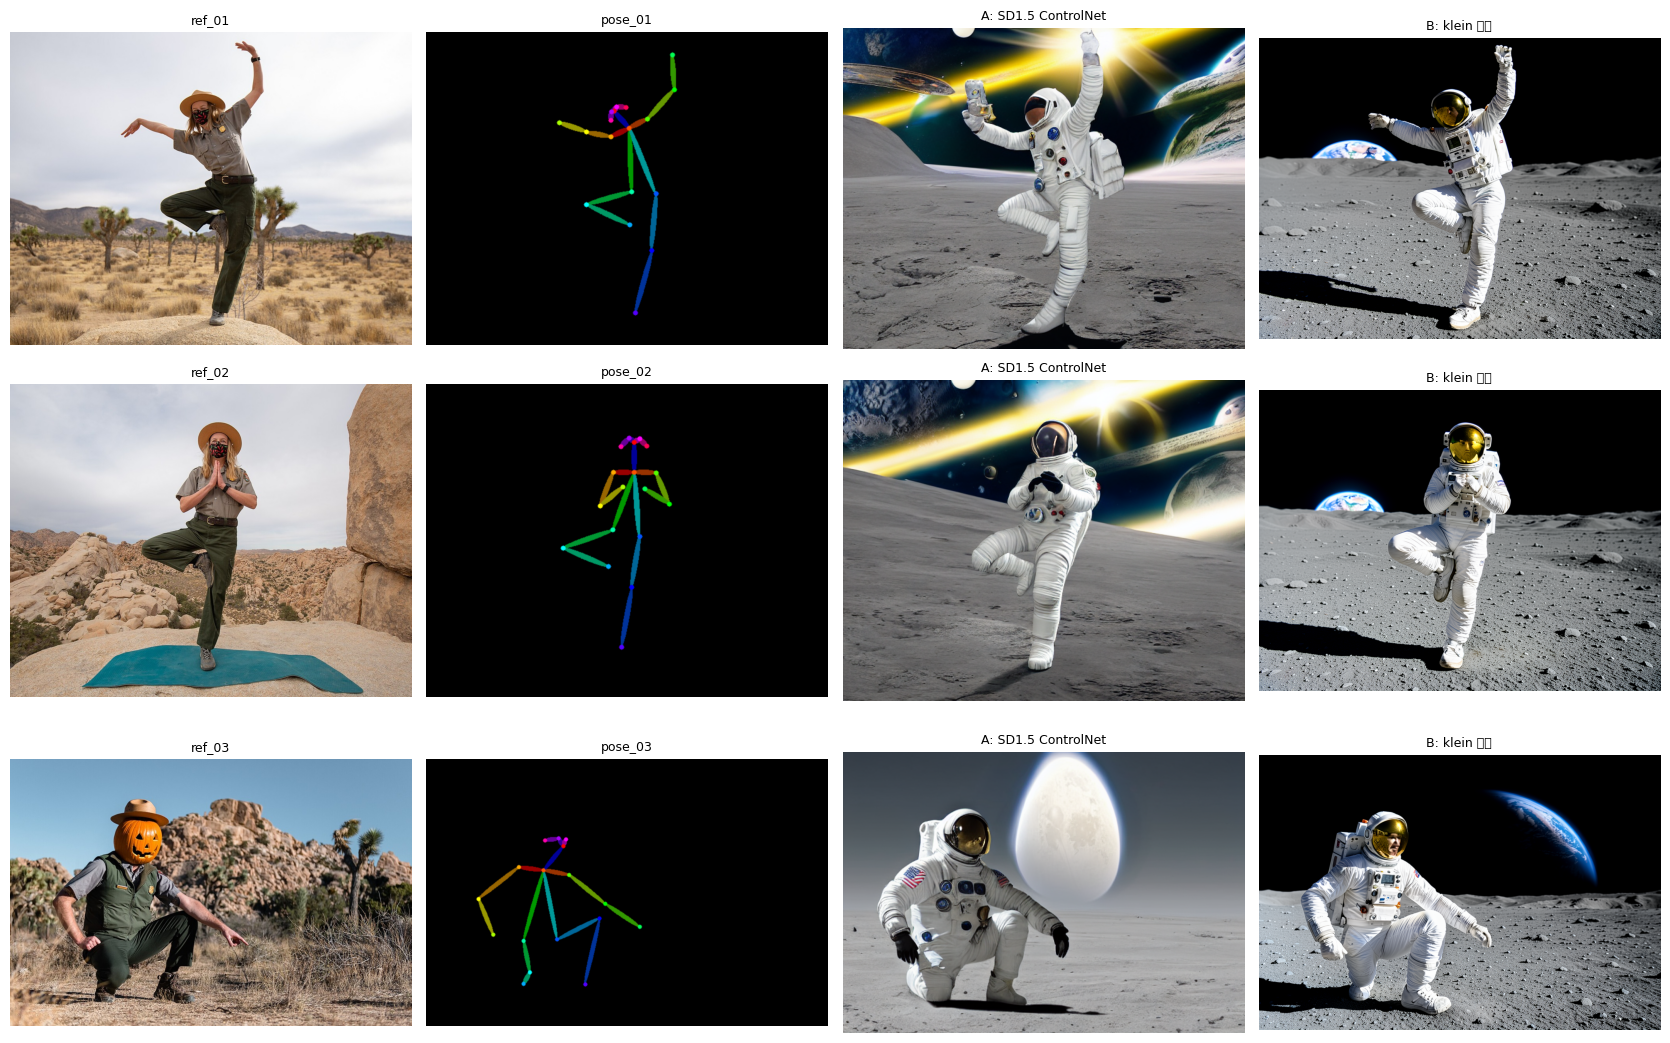

In [24]:
# [단계 11] 포즈 3개 × 두 방식
reset_log("기본")
grid, titles = [], []
for i, pose_p in enumerate(pose_paths, 1):
    print(f"\n포즈 {i:02d} — 방식 A")
    img_a, meta_a = gen_sd_controlnet(PROMPTS[MAIN_PROMPT], pose_p)
    out_a = f"{SAMPLES}/output_{i:02d}.png"; img_a.save(out_a)
    log_result(file=os.path.basename(out_a), pose=os.path.basename(pose_p), prompt_key=MAIN_PROMPT,
               prompt=PROMPTS[MAIN_PROMPT], **meta_a)

    print(f"포즈 {i:02d} — 방식 B")
    img_b, meta_b = gen_klein_reference(PROMPTS[MAIN_PROMPT], pose_p)
    out_b = f"{SAMPLES}/output_{i:02d}_klein.png"; img_b.save(out_b)
    log_result(file=os.path.basename(out_b), pose=os.path.basename(pose_p), prompt_key=MAIN_PROMPT,
               prompt=PROMPTS[MAIN_PROMPT], **meta_b)

    grid += [Image.open(ref_paths[i-1][1]), Image.open(pose_p), img_a, img_b]
    titles += [f"ref_{i:02d}", f"pose_{i:02d}", "A: SD1.5 ControlNet", "B: klein 참조"]

show(grid, titles, save_as=f"{SAMPLES}/compare_methods.png", cols=4)

## [단계 12] 실험 ① 같은 포즈 + 다른 프롬프트
이 셀이 하는 일: 포즈 01을 고정하고 프롬프트 3개를 바꿔 가며 두 방식으로 생성합니다. 시드도 고정이므로, 달라진 것은 **프롬프트 때문**입니다.

볼 것: 인물·옷·배경이 바뀌어도 **팔다리 위치가 그대로인가?** 의상(우주복, 갑옷)이 두꺼울 때 자세가 무너지지 않는가?


[astronaut]
  생성 완료 22.6초
  생성 완료 75.4초

[ballerina]
  생성 완료 22.6초
  생성 완료 76.7초

[knight]
  생성 완료 21.1초
  생성 완료 76.7초


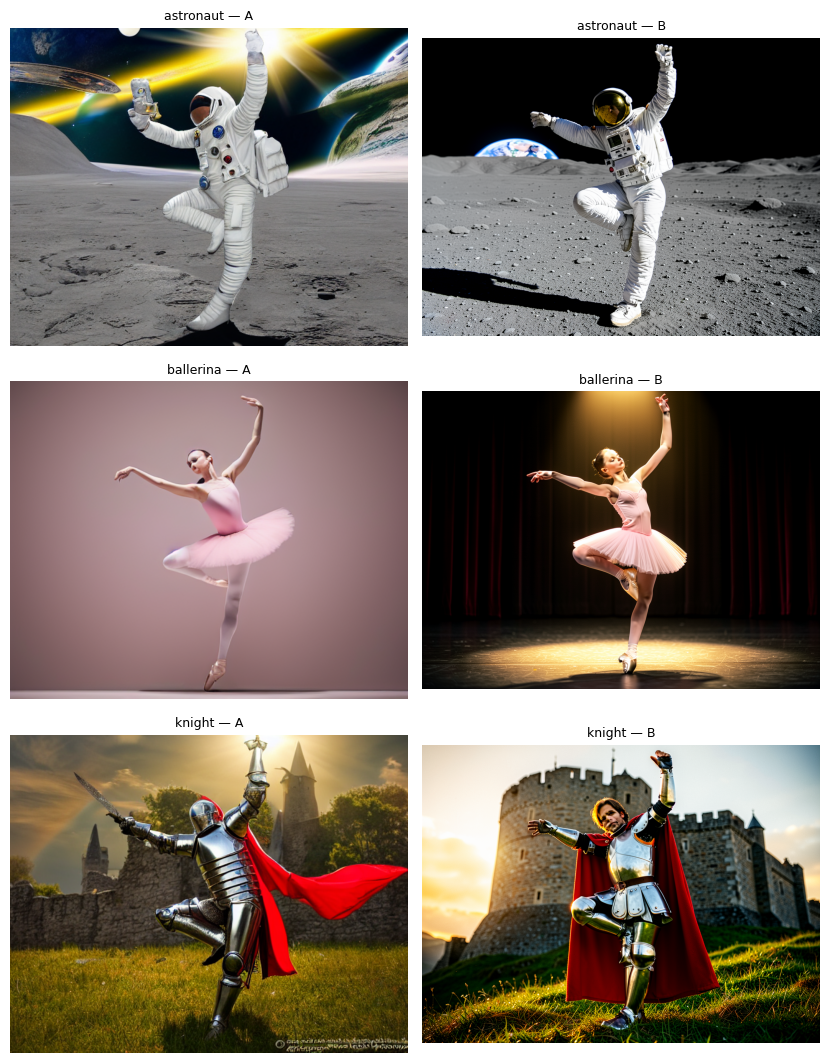

In [17]:
# [단계 12] 실험 ① — 포즈 고정, 프롬프트 변경
reset_log("1")
POSE_FIXED = pose_paths[0]
grid, titles = [], []
for key, prompt in PROMPTS.items():
    print(f"\n[{key}]")
    img_a, meta_a = gen_sd_controlnet(prompt, POSE_FIXED)
    img_b, meta_b = gen_klein_reference(prompt, POSE_FIXED)
    fa, fb = f"{SAMPLES}/exp1_pose01_{key}_A.png", f"{SAMPLES}/exp1_pose01_{key}_klein.png"
    img_a.save(fa); img_b.save(fb)
    log_result(file=os.path.basename(fa), pose="pose_01.png", prompt_key=key, prompt=prompt, experiment="1", **meta_a)
    log_result(file=os.path.basename(fb), pose="pose_01.png", prompt_key=key, prompt=prompt, experiment="1", **meta_b)
    grid += [img_a, img_b]; titles += [f"{key} — A", f"{key} — B"]

show(grid, titles, save_as=f"{SAMPLES}/compare_exp1_same_pose.png", cols=2)

## [단계 13] 실험 ② 같은 프롬프트 + 다른 포즈
이 셀이 하는 일: 프롬프트를 `knight` 로 고정하고 포즈 01~03을 바꿉니다. (기본 결과는 astronaut 였으니, 다른 피사체로 한 번 더 확인)

볼 것: 서 있는 자세(01·02)와 쪼그려 앉은 자세(03) 중 **어느 쪽에서 먼저 무너지는가?** 다리·팔이 늘어나거나 사라지지 않는가?


포즈 01
  생성 완료 22.6초
  생성 완료 76.7초

포즈 02
  생성 완료 21.4초
  생성 완료 76.7초

포즈 03
  생성 완료 21.1초
  생성 완료 73.9초


/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 52280 (\N{HANGUL SYLLABLE CAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:65: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_681/209719799.py:67: UserWarning: Glyph 52280 (\N{HANGUL SYLLABLE CAM}) missing from font(s) DejaVu Sans.
  plt.savefig(save_as, dpi=110, bbox_inches="tight")
/tmp/ipykernel_681/209719799.py:67: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  plt.savefig(save_as, dpi=110, bbox_inches="tight")


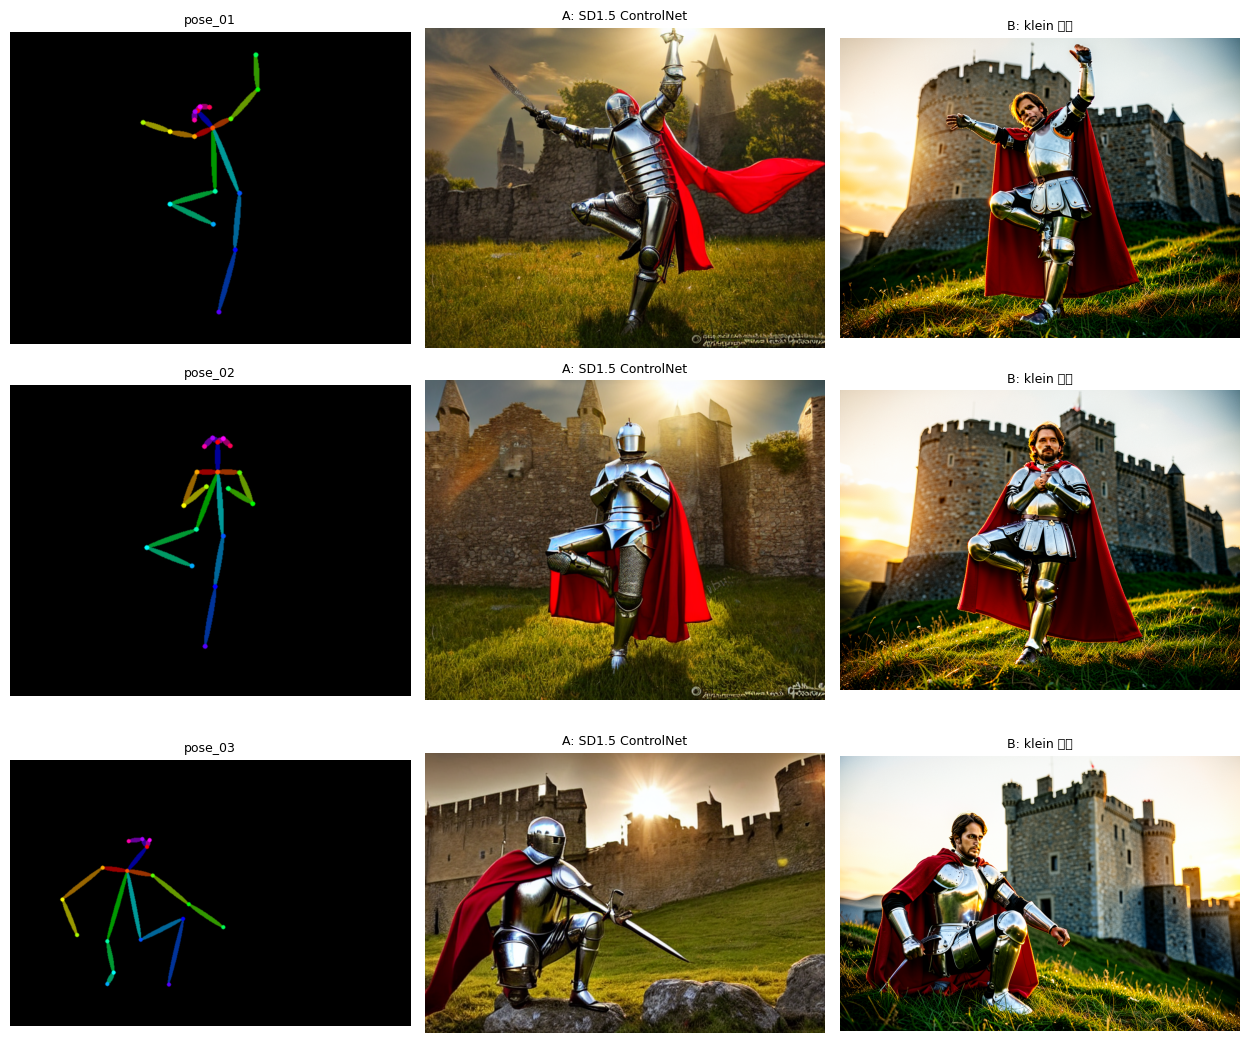

In [25]:
# [단계 13] 실험 ② — 프롬프트 고정, 포즈 변경
reset_log("2")
PROMPT_FIXED = "knight"
grid, titles = [], []
for i, pose_p in enumerate(pose_paths, 1):
    print(f"\n포즈 {i:02d}")
    img_a, meta_a = gen_sd_controlnet(PROMPTS[PROMPT_FIXED], pose_p)
    img_b, meta_b = gen_klein_reference(PROMPTS[PROMPT_FIXED], pose_p)
    fa, fb = f"{SAMPLES}/exp2_{PROMPT_FIXED}_pose{i:02d}_A.png", f"{SAMPLES}/exp2_{PROMPT_FIXED}_pose{i:02d}_klein.png"
    img_a.save(fa); img_b.save(fb)
    log_result(file=os.path.basename(fa), pose=f"pose_{i:02d}.png", prompt_key=PROMPT_FIXED, prompt=PROMPTS[PROMPT_FIXED], experiment="2", **meta_a)
    log_result(file=os.path.basename(fb), pose=f"pose_{i:02d}.png", prompt_key=PROMPT_FIXED, prompt=PROMPTS[PROMPT_FIXED], experiment="2", **meta_b)
    grid += [Image.open(pose_p), img_a, img_b]; titles += [f"pose_{i:02d}", "A: SD1.5 ControlNet", "B: klein 참조"]

show(grid, titles, save_as=f"{SAMPLES}/compare_exp2_same_prompt.png", cols=3)

## [단계 14] 실험 ③ ControlNet 강도 바꾸기 (방식 A)
이 셀이 하는 일: 포즈 02 + astronaut 고정, ControlNet `strength` 만 0.3 / 0.6 / 1.0 / 1.4 로 바꿉니다. **한 번에 한 칸만** 바꾸는 실험입니다.

볼 것: 강도가 낮으면 프롬프트가 이기고(자세가 흐트러짐), 높으면 포즈가 이기는(자세는 맞지만 그림이 딱딱해짐) 경계가 어디쯤인가?


strength=0.3
  생성 완료 22.6초

strength=0.6
  생성 완료 9.4초

strength=1.0
  생성 완료 10.5초

strength=1.4
  생성 완료 9.3초


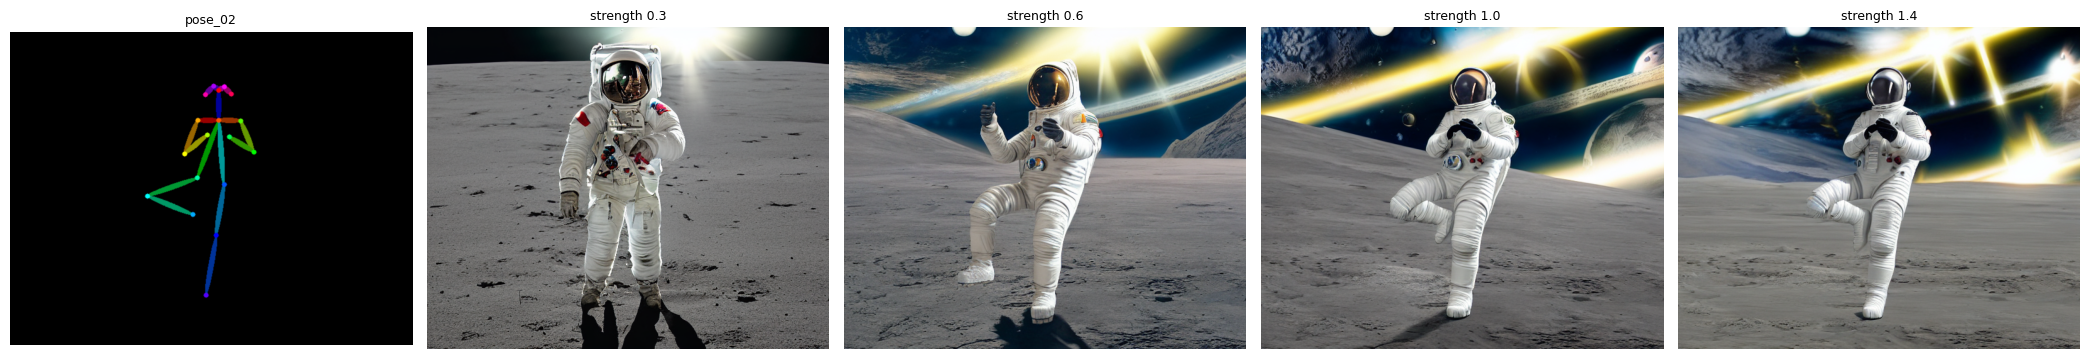

In [19]:
# [단계 14] 실험 ③ — ControlNet strength 변경
reset_log("3")
grid, titles = [], []
for s in [0.3, 0.6, 1.0, 1.4]:
    print(f"\nstrength={s}")
    img, meta = gen_sd_controlnet(PROMPTS["astronaut"], pose_paths[1], strength=s)
    f = f"{SAMPLES}/exp3_pose02_strength{s}.png"; img.save(f)
    log_result(file=os.path.basename(f), pose="pose_02.png", prompt_key="astronaut", prompt=PROMPTS["astronaut"], experiment="3", **meta)
    grid.append(img); titles.append(f"strength {s}")

show([Image.open(pose_paths[1])] + grid, ["pose_02"] + titles, save_as=f"{SAMPLES}/compare_exp3_strength.png", cols=5)

## [단계 15] prompts.md 만들기 + 결과 내려받기
이 셀이 하는 일:
1. `samples/log.json` 의 기록으로 **prompts.md** 를 만듭니다 (파일명·방식·포즈·시드·프롬프트 표).
2. `samples/` 와 `prompts.md` 를 zip 으로 묶습니다. 내려받기 줄의 주석을 풀면 내 컴퓨터로 받아집니다. → GitHub 저장소에 그대로 올리면 됩니다.

In [26]:
# [단계 15] prompts.md 생성 + zip 다운로드
import json, shutil
logs = json.load(open(LOG_PATH))
lines = ["# 테스트에 쓴 프롬프트 모음", "",
         "노트 `pose_tool.ipynb` 가 자동으로 만든 기록입니다. 모든 생성은 시드 고정(재현 가능).", "",
         "## 프롬프트 원문", ""]
for k, v in PROMPTS.items():
    lines += [f"### {k}", "", f"> {v}", ""]
lines += ["## 방식 B(klein)에서 프롬프트 앞에 붙인 포즈 지시문", "", f"> {KLEIN_POSE_HINT.strip()}", "",
          "## 생성 기록", "", "| 파일 | 실험 | 방식 | 포즈 | 프롬프트 | 시드 | 스텝 | cfg | 강도 | 크기 |", "|---|---|---|---|---|---|---|---|---|---|"]
for L in logs:
    lines.append(f"| {L['file']} | {L.get('experiment','기본')} | {L['method'].split(':')[0]} | {L['pose']} | {L['prompt_key']} | "
                 f"{L['seed']} | {L['steps']} | {L['cfg']} | {L.get('strength','-')} | {L['size']} |")
open("/content/pose-image-tool/prompts.md", "w").write("\n".join(lines) + "\n")
print("\n".join(lines[:12]), "\n...")

shutil.make_archive("/content/pose-image-tool-results", "zip", "/content/pose-image-tool")
print("zip 생성 완료: /content/pose-image-tool-results.zip")
# 내려받기: 아래 두 줄의 주석(#)을 지우고 실행 (또는 왼쪽 [파일] 패널에서 우클릭 → 다운로드)
# from google.colab import files
# files.download("/content/pose-image-tool-results.zip")

# 테스트에 쓴 프롬프트 모음

노트 `pose_tool.ipynb` 가 자동으로 만든 기록입니다. 모든 생성은 시드 고정(재현 가능).

## 프롬프트 원문

### astronaut

> A single astronaut in a white spacesuit with a gold visor, holding a balanced pose. Full-body shot, eye level, 35mm lens. Harsh sunlight from the left casting a sharp shadow. Gray lunar surface with Earth rising on the black horizon. Photorealistic NASA-style documentary photography.

### ballerina
 
...
zip 생성 완료: /content/pose-image-tool-results.zip


## [단계 16] 관찰 기록 — 무엇을 바꿔 보았고, 어떻게 달라졌는가

> 비교 그림: `samples/compare_methods.png`, `compare_exp1_same_pose.png`, `compare_exp2_same_prompt.png`, `compare_exp3_strength.png`
> 모든 생성은 시드 42 고정. 방식 A = SD1.5 + OpenPose ControlNet(25스텝, cfg 7, 강도 1.0), 방식 B = FLUX.2-klein-4B + ReferenceLatent(4스텝, cfg 4.0)

### 0. 포즈 추출(OpenPose)
- 서 있는 자세 2장(01·02)과 쪼그려 앉은 자세(03)는 관절이 잘 잡혔다. 03은 얼굴에 **호박 탈**을 쓰고 있었는데도 몸통·팔다리는 잡혔다(얼굴 점만 엉성).
- 처음 3번으로 넣었던 요가 '다운독'(머리가 아래, 얼굴이 가려진 ㅅ자 자세)은 **관절을 하나도 찾지 못해 검은 화면**이 나왔고, 두 방식 모두 그냥 서 있는 우주비행사를 그렸다. → 포즈 조건은 "추출이 성공했을 때만" 의미가 있다. 결과보다 **뼈대 그림을 먼저 확인**해야 한다.

### 1. 기본 결과 (포즈 01~03 × 방식 A/B, 프롬프트 astronaut)
- 세 포즈 모두 두 방식이 **자세를 따랐다**(01 팔 벌리고 한 다리 들기, 02 나무 자세, 03 쪼그려 앉기).
- 03에서 차이가 났다. B는 양발로 쪼그리고 오른팔을 뻗은 모습까지 참조와 비슷했고, A는 **한쪽 무릎을 땅에 댄 자세**로 바뀌었다.
- 속도(T4): A 장당 약 10~23초, B 장당 약 75초. B는 cfg 4.0이라 한 스텝에 두 번 계산하고, 7.5GB 텍스트 인코더를 오가느라 느리다.

### 2. 실험 ① 같은 포즈(01) + 다른 프롬프트 (astronaut / ballerina / knight)
- 바꾼 것: 프롬프트만 (포즈·시드·설정 고정)
- 관찰: 세 인물 모두 **팔다리 위치는 그대로** 유지됐다. 두꺼운 우주복·갑옷에서도 자세가 무너지지 않았다.
- 프롬프트 반영은 B가 앞섰다. A는 발레리나의 "어두운 극장 무대" 배경을 무시하고 **분홍 단색 배경**을 그렸고, 기사 그림 오른쪽 아래에 **워터마크 같은 글자 흔적**이 생겼다. B는 스포트라이트·무대 커튼·성·골든아워 역광까지 반영했다.
- 해석: A의 텍스트 인코더는 2021년식 CLIP(77토큰), B는 언어모델(Qwen3-4B). 긴 문장형 프롬프트일수록 B가 유리하다는 수업 내용과 맞는다.
- B의 기사는 **투구를 벗은 얼굴**로 나왔다. 프롬프트에 투구를 적지 않았으니 모델이 정한 것("안 적은 칸은 모델이 채운다").

### 3. 실험 ② 같은 프롬프트(knight) + 다른 포즈 (01 / 02 / 03)
- 바꾼 것: 포즈만
- 관찰: 세 포즈 모두 두 방식이 자세를 바꿔 따라갔다. 쪼그려 앉기(03)에서 A는 **시키지 않은 칼을 쥐여 주었고**(기사 = 칼이라는 학습 데이터의 흔한 짝), B는 맨손으로 참조 팔 모양을 더 비슷하게 유지했다.
- B는 세 장 모두 투구 없이 같은 얼굴형의 남성을 그려 **인물 일관성**은 좋았지만, 이번에도 투구는 빠졌다.

### 4. 실험 ③ ControlNet 강도 (방식 A, 포즈 02, astronaut)
- 바꾼 것: strength만 (0.3 / 0.6 / 1.0 / 1.4)
- 0.3: 포즈 무시, 그냥 서 있는 우주비행사 → 프롬프트가 이김
- 0.6: 한쪽 다리는 들었지만 팔 모양이 다름 → 절반만 따름
- 1.0: 나무 자세 일치
- 1.4: 1.0과 거의 같음. 더 올려도 이득이 없었다 → **이 포즈에서는 1.0 근처가 경계**

### 결론
- **포즈를 정확히 따르는 쪽**: 둘 다 서 있는 자세는 잘 따랐다. 확실한 제어가 필요하면 강도를 조절할 수 있는 A(ControlNet), 쪼그려 앉기처럼 접힌 자세는 이번 실험에서 B가 더 비슷했다.
- **화질·프롬프트 반영**: B(FLUX.2-klein) 우세. 배경·조명·질감이 프롬프트대로 나오고 워터마크 흔적이 없다. 대신 3~7배 느리다.
- **한계**: ① OpenPose가 못 잡는 자세(거꾸로, 얼굴 가림)는 아무 방식도 못 살린다 ② 손가락은 추출하지 않아 손 모양은 통제 안 됨 ③ B는 정식 포즈 제어가 아니라 지시문으로 유도하는 것이라 자세가 복잡해지면 보장되지 않는다 ④ 프롬프트에 안 적은 소품(칼)·옷(투구)은 모델이 마음대로 채운다.